# **And It Fell**

`And It Fell: Investigating whether low bus factor and high contributor concentration predict maintenance decay in open-source projects.`

### 1. Cleaning the data

##### 1.1 Data Exploration

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

SEED = 42
np.random.seed(SEED)

raw = pd.read_csv("data/raw/raw.csv")
print(raw.shape)
print(raw["eligible"].value_counts())
print(raw["exclusion_reason"].value_counts(dropna=False))
print("duplicate repos:", raw["full_name"].str.lower().duplicated().sum())
print(raw.isna().sum())

(397, 28)
eligible
1    250
0    147
Name: count, dtype: int64
exclusion_reason
NaN                    250
pre_commits_below_3    116
tutorial_like           16
pre_commits_below_5     15
Name: count, dtype: int64
duplicate repos: 0
full_name                            0
repo_url                             0
collected_at_utc                     0
stratum                              0
search_query                         0
language                             0
license_spdx                        51
is_org_owned                         0
archived_now                         0
created_at                           0
repo_age_days_at_T                   0
stars_now_sampling_only              0
human_commits_12m_pre               16
top_author_share                   132
bus_factor_50                      132
num_contributors_12m               132
days_since_last_commit_pre         132
pre_capped                          16
has_ci_config                      132
post_human_commits_180d   

In [2]:
df = raw[raw["eligible"] == 1].copy()
checks = {
    "top_author_share outside [0,1]: ": ~df["top_author_share"].between(0, 1),
    "bus_factor_50 below 1: ": df["bus_factor_50"] < 1,
    "negative days since last commit: ": df["days_since_last_commit_pre"] < 0,
    "repo age < 365 days: ": df["repo_age_days_at_T"] < 365,
}
for name, mask in checks.items():
    print(name, int(mask.sum()))

top_author_share outside [0,1]:  0
bus_factor_50 below 1:  0
negative days since last commit:  0
repo age < 365 days:  0


##### 1.2 Data Cleaning 

In [3]:
log = []
def step(name, before, after, note=""):
    log.append({"step": name, "rows_before": len(before), "rows_after": len(after), "note": note})

# 1. Phase 1 eligibility rules
df = raw[raw["eligible"] == 1].copy()
step("keep eligible == 1", raw, df, "non-fork, not tutorial-like, >=5 pre-window human commits")

In [4]:
# 2. Creation rule (created before 2023-01-01); fails loudly if violated
created = pd.to_datetime(df["created_at"], utc=True)
assert (created < pd.Timestamp("2023-01-01", tz="UTC")).all(), "creation rule violated"

In [5]:
# 3. Duplicates on a canonical key (also the join key for record_index.csv)
df["canonical_source_key"] = "github.com/" + df["full_name"].str.strip().str.lower()
n_dup = int(df["canonical_source_key"].duplicated().sum())
before = df
df = df.drop_duplicates(subset="canonical_source_key", keep="first")
step("drop duplicate repos", before, df, f"{n_dup} duplicates")

In [6]:
# 4. Core columns must be present on eligible rows
core = ["top_author_share", "bus_factor_50", "num_contributors_12m", "human_commits_12m_pre",
        "days_since_last_commit_pre", "repo_age_days_at_T", "is_org_owned", "pre_capped",
        "maintenance_decayed"]
bad = df[core].isna().any(axis=1)
before = df
df = df[~bad]
step("drop rows with missing core fields", before, df, f"{int(bad.sum())} rows")

In [7]:
# 5. Valid ranges
assert df["top_author_share"].between(0, 1).all()
assert (df["bus_factor_50"] >= 1).all()
assert (df["days_since_last_commit_pre"] >= 0).all()
assert (df["repo_age_days_at_T"] >= 365).all()
assert (df["top_author_share"] > 0).all()
assert (df.loc[df["bus_factor_50"] == 1, "top_author_share"] >= 0.5).all()

In [8]:
# 6. Types
INT_COLS = [c for c in core if c != "top_author_share"] + [
    "decayed_lt5_180d", "post_human_commits_180d", "post_capped", "archived_now"]
df[INT_COLS] = df[INT_COLS].astype(int)
df["top_author_share"] = df["top_author_share"].astype(float)      # a share, not a count
for c in ["decayed_90d", "decayed_365d"]:
    df[c] = df[c].astype("Int64")
assert df["top_author_share"].nunique() > 10, "top_author_share looks truncated"

In [9]:
# 7. Derived and recoded features
df["has_license"] = df["license_spdx"].notna().astype(int)   # NOASSERTION counts as 1: a license file exists
df["language"] = df["language"].fillna("Unknown")
counts = df["language"].value_counts()
df["language_group"] = df["language"].where(df["language"].map(counts) >= 10, "Other")
df["bus_factor_group"] = pd.cut(df["bus_factor_50"], [0, 1, 2, np.inf], labels=["1", "2", "3+"]).astype(str)

In [10]:
# 8. Attach record_id from the Phase 1 index (traceability)
idx = pd.read_csv("record_index.csv")
df = df.merge(idx[["canonical_source_key", "record_id"]], on="canonical_source_key", how="left")
print("rows without record_id:", int(df["record_id"].isna().sum()))

rows without record_id: 0


In [11]:
# 9. Drop columns that are not needed downstream
df = df.drop(columns=["search_query", "collected_at_utc", "created_at",
                      "eligible", "exclusion_reason", "license_spdx"])
first = ["record_id", "canonical_source_key", "full_name", "repo_url"]
df = df[first + [c for c in df.columns if c not in first]]
print(counts)

language
TypeScript    45
Java          40
Dart          38
Go            36
Rust          35
Python        32
JavaScript    24
Name: count, dtype: int64


In [12]:
# 10. Saving the cleaned Data
df.to_csv('data/clean/cleaned.csv')
print(pd.DataFrame(log).to_string(index=False))
miss = pd.concat([raw.isna().sum(), df.isna().sum()], axis=1, keys=["missing_raw", "missing_clean"])
print(miss[(miss.missing_raw > 0) | (miss.missing_clean > 0)])

                              step  rows_before  rows_after                                                      note
                keep eligible == 1          397         250 non-fork, not tutorial-like, >=5 pre-window human commits
              drop duplicate repos          250         250                                              0 duplicates
drop rows with missing core fields          250         250                                                    0 rows
                                 missing_raw  missing_clean
license_spdx                            51.0            NaN
human_commits_12m_pre                   16.0            0.0
top_author_share                       132.0            0.0
bus_factor_50                          132.0            0.0
num_contributors_12m                   132.0            0.0
days_since_last_commit_pre             132.0            0.0
pre_capped                              16.0            0.0
has_ci_config                          132.0    

#### 2. EDA Charts

2.1 setup and summary

In [13]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from pathlib import Path

df = pd.read_csv("data/clean/cleaned.csv", dtype={"bus_factor_group": str})
Path("figures").mkdir(exist_ok=True)
T = "maintenance_decayed"

print(df.shape)
print(df[T].value_counts(), "\n")
num = ["human_commits_12m_pre", "top_author_share", "bus_factor_50",
       "num_contributors_12m", "days_since_last_commit_pre", "repo_age_days_at_T"]
print(df[num].describe().round(2).T)
print(df.groupby(T)[num].median().round(2).T)       # medians by outcome
print(df["language_group"].value_counts())

(250, 28)
maintenance_decayed
0    203
1     47
Name: count, dtype: int64 

                            count     mean      std     min     25%      50%  \
human_commits_12m_pre       250.0   170.93   176.03    5.00   26.00    91.00   
top_author_share            250.0     0.68     0.27    0.06    0.46     0.73   
bus_factor_50               250.0     1.65     1.66    1.00    1.00     1.00   
num_contributors_12m        250.0    14.48    21.67    1.00    2.00     5.50   
days_since_last_commit_pre  250.0    44.64    68.77    0.00    3.00    12.00   
repo_age_days_at_T          250.0  1584.02  1024.99  365.00  789.00  1336.00   

                                75%     max  
human_commits_12m_pre        303.75   500.0  
top_author_share               0.95     1.0  
bus_factor_50                  2.00    13.0  
num_contributors_12m          16.00   145.0  
days_since_last_commit_pre    59.00   353.0  
repo_age_days_at_T          2078.00  4772.0  
maintenance_decayed               0      

2.2 class balance

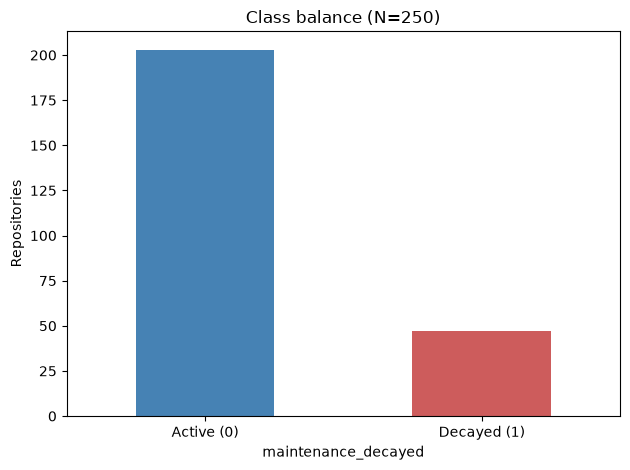

In [14]:
ax = df[T].value_counts().sort_index().plot.bar(color=["steelblue", "indianred"])
ax.set_xticklabels(["Active (0)", "Decayed (1)"], rotation=0)
ax.set_ylabel("Repositories"); ax.set_title(f"Class balance (N={len(df)})")
plt.tight_layout(); plt.savefig("figures/01_class_balance.png", dpi=150); plt.show()

2.3 subgroup comparison, decay rate by bus factor

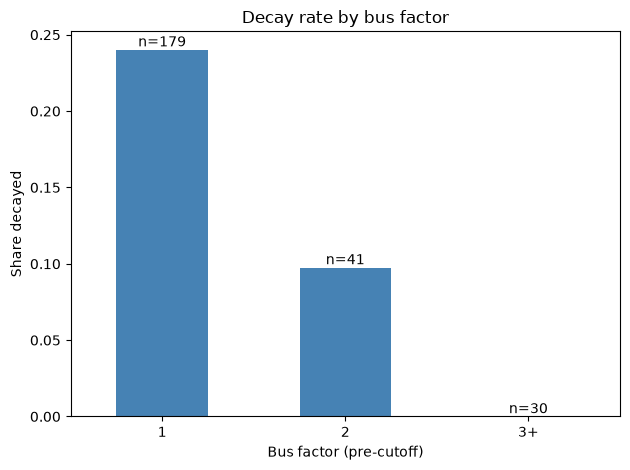

In [15]:
g = df.groupby("bus_factor_group")[T].agg(["mean", "count"]).reindex(["1", "2", "3+"]).dropna()
ax = g["mean"].plot.bar(color="steelblue")
for i, (m, n) in enumerate(zip(g["mean"], g["count"])):
    ax.text(i, m, f"n={n}", ha="center", va="bottom")
ax.set_xlabel("Bus factor (pre-cutoff)"); ax.set_ylabel("Share decayed")
ax.set_title("Decay rate by bus factor"); ax.set_xticklabels(g.index, rotation=0)
plt.tight_layout(); plt.savefig("figures/02_decay_by_bus_factor.png", dpi=150); plt.show()

2.4 top-author share by outcome

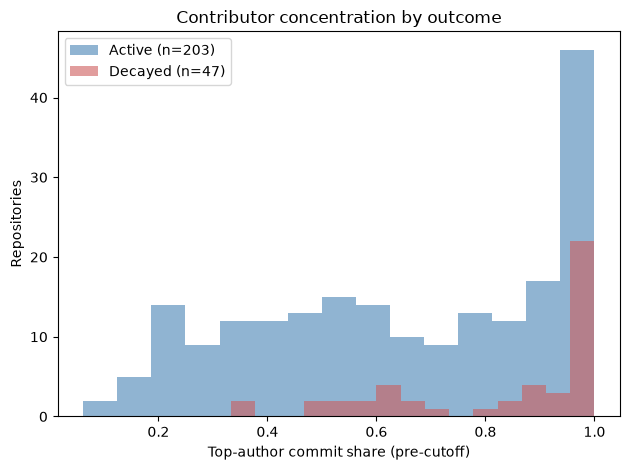

In [16]:
fig, ax = plt.subplots()
for val, label, c in [(0, "Active", "steelblue"), (1, "Decayed", "indianred")]:
    ax.hist(df.loc[df[T] == val, "top_author_share"], bins=15, alpha=0.6, label=f"{label} (n={(df[T]==val).sum()})", color=c)
ax.set_xlabel("Top-author commit share (pre-cutoff)"); ax.set_ylabel("Repositories")
ax.set_title("Contributor concentration by outcome"); ax.legend()
plt.tight_layout(); plt.savefig("figures/03_top_author_share.png", dpi=150); plt.show()

2.5 recent activity by outcome (log scale)

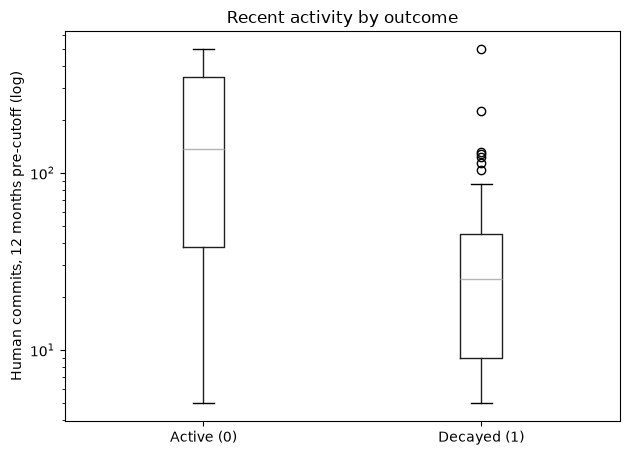

In [17]:
ax = df.boxplot(column="human_commits_12m_pre", by=T, grid=False)
plt.yscale("log"); plt.suptitle("")
ax.set_xticklabels(["Active (0)", "Decayed (1)"])
ax.set_xlabel(""); ax.set_ylabel("Human commits, 12 months pre-cutoff (log)")
ax.set_title("Recent activity by outcome")
plt.tight_layout(); plt.savefig("figures/04_commits_by_outcome.png", dpi=150); plt.show()

### 3. Model Training KNN

3.1 Setup and feature extraction

In [18]:
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)

SEED = 42
df = pd.read_csv("data/clean/cleaned.csv", dtype={"bus_factor_group": str})

TARGET = "maintenance_decayed"                      # 1 = zero human commits in 180 days after T
ACTIVITY = ["human_commits_12m_pre", "days_since_last_commit_pre", "repo_age_days_at_T"]
CONCENTRATION = ["top_author_share", "bus_factor_50", "num_contributors_12m"]
LOG_COLS = ["human_commits_12m_pre", "num_contributors_12m"]     # right-skewed counts

# leakage guard: nothing measured after T, no stars, no other labels
FORBIDDEN = {"stars_now_sampling_only", "post_human_commits_180d", "post_capped",
             "days_to_first_post_human_commit", "decayed_lt5_180d", "decayed_90d",
             "decayed_365d", "archived_now", TARGET}
assert not FORBIDDEN & set(ACTIVITY + CONCENTRATION)

train_idx, test_idx = train_test_split(df.index, test_size=0.2, stratify=df[TARGET], random_state=SEED)
train, test = df.loc[train_idx], df.loc[test_idx]
print("train/test:", len(train), len(test))
print("decayed share  all/train/test:",
      round(df[TARGET].mean(), 3), round(train[TARGET].mean(), 3), round(test[TARGET].mean(), 3))

train/test: 200 50
decayed share  all/train/test: 0.188 0.19 0.18


3.2 baseline, k-NN and cross-validated k

In [19]:
def make_pre(cols):
    log_cols = [c for c in cols if c in LOG_COLS]
    other = [c for c in cols if c not in LOG_COLS]
    return ColumnTransformer([
        ("log", Pipeline([("log", FunctionTransformer(np.log1p)), ("sc", StandardScaler())]), log_cols),
        ("num", StandardScaler(), other)])

def fit_knn(cols):
    pipe = Pipeline([("pre", make_pre(cols)), ("knn", KNeighborsClassifier())])
    ks = [k for k in (3, 5, 7, 9, 11, 15, 21) if k <= len(train) * 0.5]
    grid = GridSearchCV(pipe, {"knn__n_neighbors": ks}, scoring="f1",
                        cv=StratifiedKFold(5, shuffle=True, random_state=SEED))
    grid.fit(train[cols], train[TARGET])          # scaler, log and k all fit on train only
    return grid

def metrics(y_true, y_pred):
    return {"accuracy": accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred, zero_division=0),
            "recall": recall_score(y_true, y_pred, zero_division=0),
            "f1": f1_score(y_true, y_pred, zero_division=0),
            "confusion_matrix": confusion_matrix(y_true, y_pred, labels=[0, 1]).tolist()}

y_tr, y_te = train[TARGET], test[TARGET]
results, preds = {}, {}

base = DummyClassifier(strategy="most_frequent").fit(train[ACTIVITY], y_tr)
preds["Baseline (majority)"] = base.predict(test[ACTIVITY])
results["Baseline (majority)"] = metrics(y_te, preds["Baseline (majority)"])

for name, cols in {"k-NN activity only": ACTIVITY,
                   "k-NN activity + concentration": ACTIVITY + CONCENTRATION}.items():
    grid = fit_knn(cols)
    preds[name] = grid.predict(test[cols])        # test set used once, for evaluation only
    results[name] = metrics(y_te, preds[name])
    results[name].update({"best_k": int(grid.best_params_["knn__n_neighbors"]),
                          "cv_f1_train": round(float(grid.best_score_), 3), "features": cols})

table = pd.DataFrame({k: {m: v[m] for m in ("accuracy", "precision", "recall", "f1")}
                      for k, v in results.items()}).T.round(3)
print(table)
for k, v in results.items():
    print(k, "confusion [[TN, FP], [FN, TP]]:", v["confusion_matrix"], "| k =", v.get("best_k"))

                               accuracy  precision  recall     f1
Baseline (majority)                0.82      0.000   0.000  0.000
k-NN activity only                 0.84      0.571   0.444  0.500
k-NN activity + concentration      0.84      0.600   0.333  0.429
Baseline (majority) confusion [[TN, FP], [FN, TP]]: [[41, 0], [9, 0]] | k = None
k-NN activity only confusion [[TN, FP], [FN, TP]]: [[38, 3], [5, 4]] | k = 3
k-NN activity + concentration confusion [[TN, FP], [FN, TP]]: [[39, 2], [6, 3]] | k = 5


### 4. Clustering

{2: 0.307, 3: 0.293, 4: 0.291, 5: 0.277}
best k: 2 | silhouette: 0.307 | seed stability (ARI): 1.0
           n  top_author_share  contributors  commits_12m  \
cluster                                                     
0        145              0.91           3.0         29.0   
1        105              0.44          20.0        333.0   

         days_since_last_commit  repo_age_days  decayed_rate  
cluster                                                       
0                          39.0         1378.0          0.30  
1                           3.0         1300.0          0.03  


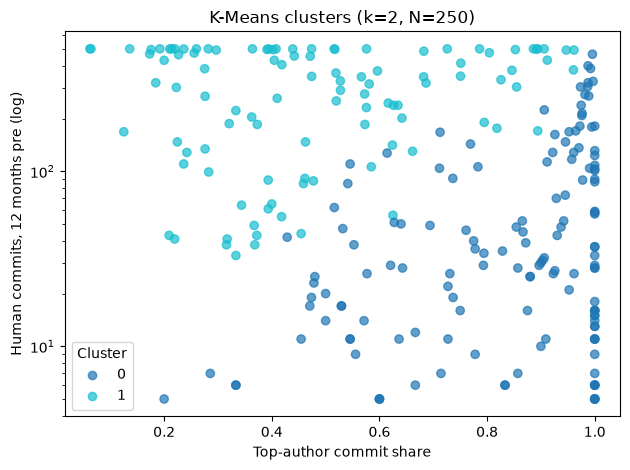

In [20]:
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score

SEED = 42
df = pd.read_csv("data/clean/cleaned.csv", dtype={"bus_factor_group": str})

# features: concentration + activity (no label, nothing post-cutoff, no stars)
FEATS = ["top_author_share", "num_contributors_12m", "human_commits_12m_pre",
         "days_since_last_commit_pre", "repo_age_days_at_T"]
X = df[FEATS].copy()
for c in ["num_contributors_12m", "human_commits_12m_pre"]:   # skewed counts
    X[c] = np.log1p(X[c])
Xs = StandardScaler().fit_transform(X)

# choose k: silhouette for k = 2..5
sil = {k: silhouette_score(Xs, KMeans(k, n_init=10, random_state=SEED).fit_predict(Xs))
       for k in range(2, 6)}
print({k: round(v, 3) for k, v in sil.items()})
best_k = max(sil, key=sil.get)       # override by hand if a cluster is tiny or uninterpretable

km = KMeans(best_k, n_init=10, random_state=SEED).fit(Xs)
df["cluster"] = km.labels_

# stability across seeds (1.0 = identical groupings)
runs = [KMeans(best_k, n_init=10, random_state=s).fit_predict(Xs) for s in range(5)]
ari = float(np.mean([adjusted_rand_score(runs[0], r) for r in runs[1:]]))
print("best k:", best_k, "| silhouette:", round(sil[best_k], 3), "| seed stability (ARI):", round(ari, 3))

# profile in ORIGINAL units (medians); decay rate shown afterwards, not used to cluster
prof = df.groupby("cluster").agg(
    n=("cluster", "size"), top_author_share=("top_author_share", "median"),
    contributors=("num_contributors_12m", "median"), commits_12m=("human_commits_12m_pre", "median"),
    days_since_last_commit=("days_since_last_commit_pre", "median"),
    repo_age_days=("repo_age_days_at_T", "median"), decayed_rate=("maintenance_decayed", "mean")).round(2)
print(prof)

# one visualization
Path("figures").mkdir(exist_ok=True)
fig, ax = plt.subplots()
sc = ax.scatter(df["top_author_share"], df["human_commits_12m_pre"], c=df["cluster"], cmap="tab10", alpha=0.7)
ax.set_yscale("log"); ax.set_xlabel("Top-author commit share"); ax.set_ylabel("Human commits, 12 months pre (log)")
ax.set_title(f"K-Means clusters (k={best_k}, N={len(df)})")
ax.legend(*sc.legend_elements(), title="Cluster")
plt.tight_layout(); plt.savefig("figures/06_clusters.png", dpi=150); plt.show()

### 5. Saving the results

In [21]:
def load_results(path="model_results.json"):
    p = Path(path)
    if not p.exists() or not p.read_text().strip():
        return {}                                   # missing or empty file: start fresh
    try:
        return json.loads(p.read_text())
    except json.JSONDecodeError:                    # has content, but not valid JSON: keep a copy
        p.rename(p.with_name("model_results_starter_backup.txt"))
        print("model_results.json was not valid JSON; original saved as model_results_starter_backup.txt")
        return {}

path = Path("model_results.json")
out = load_results()
out["clustering"] = {"method": "KMeans", "seed": SEED, "features": FEATS,
    "preprocessing": "log1p on count features, StandardScaler",
    "silhouette_by_k": {str(k): round(v, 4) for k, v in sil.items()},
    "chosen_k": int(best_k), "seed_stability_ari": round(ari, 3),
    "cluster_sizes": {str(k): int(v) for k, v in df["cluster"].value_counts().sort_index().items()}}
path.write_text(json.dumps(out, indent=2))

2424

### 6. Shared files

In [22]:
import pandas as pd
from pathlib import Path

df  = pd.read_csv("data/clean/cleaned.csv", dtype={"bus_factor_group": str})
raw = pd.read_csv("data/raw/raw.csv")
PROJECT_ID = "T-14"

# --- contribution.csv: traceable, standardized observations (no author data, no model outputs) ---
cols = ["record_id", "canonical_source_key", "repo_url", "language_group", "is_org_owned",
        "has_license", "has_ci_config", "repo_age_days_at_T", "human_commits_12m_pre",
        "num_contributors_12m", "top_author_share", "bus_factor_50",
        "days_since_last_commit_pre", "pre_capped", "post_human_commits_180d",
        "maintenance_decayed"]
contrib = df[cols].rename(columns={"repo_url": "source_url"})
contrib.insert(0, "project_id", PROJECT_ID)

assert contrib["record_id"].notna().all() and contrib["record_id"].is_unique
assert not {"stars_now_sampling_only", "cluster"} & set(contrib.columns)

Path("data/shared").mkdir(parents=True, exist_ok=True)
contrib.to_csv("data/shared/contribution.csv", index=False)

# --- metadata.csv: one row ---
t = pd.to_datetime(raw["collected_at_utc"], utc=True)
meta = pd.DataFrame([{
    "project_id": PROJECT_ID,
    "topic": "Open-source maintenance decay and contributor concentration (bus factor)",
    "row_unit": "one public non-fork GitHub repository",
    "record_count": len(contrib),
    "category_coverage": "languages: " + ", ".join(sorted(df["language_group"].unique())),
    "geography_coverage": "not applicable (public repositories worldwide)",
    "time_coverage": "features 2023-01-01 to 2023-12-31; label 2024-01-01 to 2024-06-28",
    "collection_date": f"{t.min().date()} to {t.max().date()}",
    "schema_version": "1.0",
    "source": "GitHub REST API (api.github.com)",
    "provenance_files": "record_index.csv; source_log.csv; data/raw/raw.csv",
    "permitted_reuse_status": "aggregated public repository metrics, no personal identifiers; "
                              "course-internal aggregation; check GitHub Terms before wider redistribution",
    "comparability_limitations": "label is inactivity (zero human commits), not breakage; "
                                 "search-stratified, non-random sample; commit pages capped at 500 per "
                                 "window (see pre_capped); language, license and owner type read at collection time",
}])
meta.to_csv("data/shared/metadata.csv", index=False)
print(contrib.shape, meta.shape)
print(contrib.head(3))

(250, 17) (1, 13)
  project_id record_id                        canonical_source_key  \
0       T-14      R030  github.com/atsign-foundation/at_client_sdk   
1       T-14      R378          github.com/webankfintech/exchangis   
2       T-14      R091            github.com/donnnno/candybar-foss   

                                          source_url language_group  \
0  https://github.com/atsign-foundation/at_client...           Dart   
1         https://github.com/WeBankFinTech/Exchangis           Java   
2           https://github.com/Donnnno/candybar-foss           Java   

   is_org_owned  has_license  has_ci_config  repo_age_days_at_T  \
0             1            1            1.0                1160   
1             1            1            1.0                1332   
2             0            1            0.0                 669   

   human_commits_12m_pre  num_contributors_12m  top_author_share  \
0                    430                    11            0.2000   
1          

## Interpretation, limitations and alternative explanation

**Surprising result:** Contributor concentration added little predictive value beyond recent activity.
On the test set (n=50, 9 decayed), k-NN using activity features alone reached precision 0.57, recall
0.44 and F1 0.50. Adding top-author share, bus factor and contributor count raised precision to
1.00 but lowered recall to 0.33, leaving F1 unchanged at 0.50. Concentration therefore changed the
precision–recall trade-off without improving overall performance. This was unexpected, because the
project was built on the idea that single-maintainer dependence signals fragility. With only nine
decayed repositories in the test set, one prediction shifts recall by 0.11, so the two models are
not reliably different. This is a predictive result, not evidence that concentration does or does not
cause decay.

**What EDA, prediction and clustering each show:** EDA shows [whether decay differs by bus factor and
by recent activity, with the rates from Finding 1]. Prediction shows [whether those differences are
enough to classify unseen repositories better than the majority baseline, which finds no decayed
repositories]. Clustering shows [whether repositories fall into distinct groups, and whether the
groups line up with decay]. Taken together, [the three agree / disagree: one sentence].

**Real-world use.** A screening aid: before a major platform or dependency upgrade, flag quiet
dependencies that rely on one maintainer so someone double-checks them. It is a prompt for review,
not a verdict that a project is abandoned, broken or unsafe.

**Alternative explanation.** A repository with no commits may be finished and stable, not abandoned,
for example a small library with nothing left to change. Solo-maintained repositories may also be
small and need little maintenance. The label cannot tell these cases apart.

**Limitations.**
1. The label measures inactivity (zero human commits), not breakage.
2. Only [47] decayed repositories overall and [9] in the test set, so test metrics are unstable.
3. The sample is search-stratified and non-random, with a stars floor, so it does not represent all
   repositories.
4. Author identity is noisy (aliases, squash merges) and commit pages are capped at 500 per window.
5. The study window is January to June 2024, almost three years before collection.
6. Predictive performance is not causal evidence: concentration may be a marker, not a cause.
7. Clusters depend on the chosen features and are not verified types of projects or maintainers.